# Quiz 1

- Un viajero que acaba de regresar de Europa gastó $30 diarios en Inglaterra, $20 diarios
en Francia y $20 diarios en España por concepto de hospedaje. En comida gastó $20 diarios en Inglaterra, $30 diarios en Francia y $20 diarios en España. Sus gastos adicionales
fueron de $10 diarios en cada país. Los registros del viajero indican que gastó un total de
$340 en hospedaje, $320 en comida y $140 en gastos adicionales durante su viaje por estos
tres países. Calcule el número de días que pasó el viajero en cada país o muestre que los
registros son incorrectos debido a que las cantidades gastadas no son compatibles una con
la otra.

## Planteamiento del sistema de ecuaciones

Sean:
- $x$ = número de días en **Inglaterra**
- $y$ = número de días en **Francia**
- $z$ = número de días en **España**

De los gastos de **hospedaje** ($30, $20, $20 diarios y total $340):
$$30x + 20y + 20z = 340$$

De los gastos de **comida** ($20, $30, $20 diarios y total $320):
$$20x + 30y + 20z = 320$$

De los gastos **adicionales** ($10 diarios en cada país y total $140):
$$10x + 10y + 10z = 140$$

Sistema de ecuaciones:
$$
\begin{cases}
30x + 20y + 20z = 340 \\
20x + 30y + 20z = 320 \\
10x + 10y + 10z = 140
\end{cases}
$$

Matriz aumentada asociada:
$$
\left[\begin{array}{ccc|c}
30 & 20 & 20 & 340 \\
20 & 30 & 20 & 320 \\
10 & 10 & 10 & 140
\end{array}\right]
$$

In [1]:
import sympy as sp

# Matriz de coeficientes y vector de términos independientes
A = sp.Matrix([
    [30, 20, 20],
    [20, 30, 20],
    [10, 10, 10]
])
b = sp.Matrix([340, 320, 140])

# Matriz aumentada y forma escalonada reducida (Gauss-Jordan)
aug = A.row_join(b)
rref, pivots = aug.rref()

print("Matriz aumentada:")
sp.pprint(aug)
print("\nForma escalonada reducida (RREF):")
sp.pprint(rref)
print("\nColumnas pivote:", pivots)
print("Rango de A:", A.rank(), " | Rango de la aumentada:", aug.rank())


Matriz aumentada:
⎡30  20  20  340⎤
⎢               ⎥
⎢20  30  20  320⎥
⎢               ⎥
⎣10  10  10  140⎦

Forma escalonada reducida (RREF):
⎡1  0  0  6⎤
⎢          ⎥
⎢0  1  0  4⎥
⎢          ⎥
⎣0  0  1  4⎦

Columnas pivote: (0, 1, 2)
Rango de A: 3  | Rango de la aumentada: 3


In [2]:
x, y, z = sp.symbols('x y z')
sol = sp.solve([sp.Eq(30*x+20*y+20*z, 340),
                 sp.Eq(20*x+30*y+20*z, 320),
                 sp.Eq(10*x+10*y+10*z, 140)], [x, y, z])
print("Solución:", sol)

# Verificación de los totales
xv, yv, zv = sol[x], sol[y], sol[z]
print("\nComprobación:")
print("Hospedaje:", 30*xv+20*yv+20*zv, "(debe ser 340)")
print("Comida:   ", 20*xv+30*yv+20*zv, "(debe ser 320)")
print("Adicional:", 10*xv+10*yv+10*zv, "(debe ser 140)")


Solución: {x: 6, y: 4, z: 4}

Comprobación:
Hospedaje: 340 (debe ser 340)
Comida:    320 (debe ser 320)
Adicional: 140 (debe ser 140)


## Conclusión

El sistema es **consistente** (rango de $A$ = rango de la matriz aumentada = 3), por lo tanto tiene **solución única**. Los registros del viajero **sí son compatibles**.

$$x = 6, \quad y = 4, \quad z = 4$$

El viajero pasó **6 días en Inglaterra**, **4 días en Francia** y **4 días en España**.

# Quiz 2


- Hallar la factorización $LU$ de la matriz dada

$$A = \left[\begin{array}{rrr} 
5 & -7 & -5 \\
20 & 24 & -30 \\
-20 & - 24 & 22

\end{array}\right]
$$

In [3]:
import sympy as sp
sp.init_printing
# Matriz A
A = sp.Matrix([
    [5, -7, -5],
    [20, 24, -30],
    [-20, -24, 22]
])

n = A.shape[0]
U = A.copy()
L = sp.eye(n)

print("Matriz inicial A = U(0):")
U


Matriz inicial A = U(0):


Matrix([
[  5,  -7,  -5],
[ 20,  24, -30],
[-20, -24,  22]])

### Paso 1: eliminar la columna 1 debajo del pivote $a_{11}=5$

Multiplicadores:
$$m_{21} = \dfrac{a_{21}}{a_{11}}, \qquad m_{31} = \dfrac{a_{31}}{a_{11}}$$

Operaciones fila:
$$F_2 \leftarrow F_2 - m_{21} F_1, \qquad F_3 \leftarrow F_3 - m_{31} F_1$$

In [4]:
# --- Paso 1: pivote columna 1 ---
piv = U[0, 0]

m21 = U[1, 0] / piv
m31 = U[2, 0] / piv
print("m21 =", m21, " | m31 =", m31)

U[1, :] = U[1, :] - m21 * U[0, :]
U[2, :] = U[2, :] - m31 * U[0, :]

L[1, 0] = m21
L[2, 0] = m31

U

m21 = 4  | m31 = -4


Matrix([
[5,  -7,  -5],
[0,  52, -10],
[0, -52,   2]])

In [5]:
L

Matrix([
[ 1, 0, 0],
[ 4, 1, 0],
[-4, 0, 1]])

### Paso 2: eliminar la columna 2 debajo del pivote $a_{22}$

Multiplicador:
$$m_{32} = \dfrac{a_{32}}{a_{22}}$$

Operación fila:
$$F_3 \leftarrow F_3 - m_{32} F_2$$

In [6]:
# --- Paso 2: pivote columna 2 ---
piv = U[1, 1]

m32 = U[2, 1] / piv
print("m32 =", m32)

U[2, :] = U[2, :] - m32 * U[1, :]

L[2, 1] = m32

U


m32 = -1


Matrix([
[5, -7,  -5],
[0, 52, -10],
[0,  0,  -8]])

In [7]:
L

Matrix([
[ 1,  0, 0],
[ 4,  1, 0],
[-4, -1, 1]])

### Verificación: $A = LU$

Comprobamos con SymPy que el producto $LU$ reproduce la matriz original, y además contrastamos con el método `LUdecomposition` incorporado en SymPy.

In [8]:
# Verificación manual: L*U debe ser igual a A
L*U

Matrix([
[  5,  -7,  -5],
[ 20,  24, -30],
[-20, -24,  22]])

## Conclusión

No fue necesario intercambiar filas (no hubo pivoteo), por lo que la factorización $A = LU$ es:

$$
L = \begin{pmatrix} 1 & 0 & 0 \\ 4 & 1 & 0 \\ -4 & -1 & 1 \end{pmatrix}, \qquad
U = \begin{pmatrix} 5 & -7 & -5 \\ 0 & 52 & -10 \\ 0 & 0 & -8 \end{pmatrix}
$$

con $A = LU$, $L$ triangular inferior con unos en la diagonal (contiene los multiplicadores $m_{21}=4$, $m_{31}=-4$, $m_{32}=-1$) y $U$ triangular superior (resultado de la eliminación gaussiana).

# Quiz 3

- Considere el sistema

$$
\begin{cases}
2x - y - kz = 0 \\
x - y - 2z = 1 \\
-x \quad\ \ + 2z = k
\end{cases}
$$

Hallar los valores de $k$ para que el sistema tenga **única solución**, **no tenga solución** e **infinitas soluciones**.

## Matriz de coeficientes y determinante

$$
A = \left[\begin{array}{ccc}
2 & -1 & -k \\
1 & -1 & -2 \\
-1 & 0 & 2
\end{array}\right], \qquad
b = \left[\begin{array}{c} 0 \\ 1 \\ k \end{array}\right]
$$

El sistema tiene **solución única** si $\det(A) \neq 0$. Calculamos $\det(A)$ en función de $k$ con SymPy.

In [9]:
import sympy as sp

k = sp.symbols('k')

A = sp.Matrix([
    [2, -1, -k],
    [1, -1, -2],
    [-1, 0, 2]
])
b = sp.Matrix([0, 1, k])

det_A = sp.simplify(A.det())
print("det(A) =", det_A)

k_criticos = sp.solve(sp.Eq(det_A, 0), k)
print("Valor(es) de k que anulan el determinante:", k_criticos)


det(A) = k - 4
Valor(es) de k que anulan el determinante: [4]


Como $\det(A) = k - 4$, el sistema tiene **solución única** para todo $k \neq 4$.

Para $k = 4$ el sistema es singular; hay que estudiar la matriz aumentada para decidir entre **infinitas soluciones** o **ningún solución** (comparando el rango de $A$ con el rango de la aumentada).

In [10]:
A_k = A.subs(k, 4)
b_k = b.subs(k, 4)
aug_k = A_k.row_join(b_k)

rref_k, pivots_k = aug_k.rref()

print("Matriz aumentada con k = 4:")
sp.pprint(aug_k)
print("\nForma escalonada reducida (RREF):")
sp.pprint(rref_k)

print("\nRango de A:", A_k.rank(), " | Rango de la aumentada:", aug_k.rank())


Matriz aumentada con k = 4:
⎡2   -1  -4  0⎤
⎢             ⎥
⎢1   -1  -2  1⎥
⎢             ⎥
⎣-1  0   2   4⎦

Forma escalonada reducida (RREF):
⎡1  0  -2  0⎤
⎢           ⎥
⎢0  1  0   0⎥
⎢           ⎥
⎣0  0  0   1⎦

Rango de A: 2  | Rango de la aumentada: 3


## Conclusión

- **Solución única:** para todo $k \neq 4$, ya que $\det(A) = k-4 \neq 0$.
- **Sin solución:** para $k = 4$, pues $\text{rango}(A) = 2 < \text{rango}(A|b) = 3$ (sistema inconsistente).
- **Infinitas soluciones:** no existe ningún valor de $k$ que produzca infinitas soluciones, ya que el único caso singular ($k=4$) resulta inconsistente.

# Quiz 4

Sobre $\mathbb{R}^2$ se definen las siguientes operaciones de **suma** $\oplus$ y **producto por escalar** $\odot$:

$$
(a, b) \oplus (c, d) = (a\,c,\; b + d), \qquad
\alpha \odot (a, b) = (a^{\alpha},\; \alpha\, b), \qquad \alpha \in \mathbb{R}
$$

Es decir, la "suma" **multiplica** las primeras componentes y **suma** las segundas; el "producto por escalar" **eleva** la primera componente al escalar y **multiplica** por el escalar la segunda.

1. Calcular $\;2 \odot (2, 4) \oplus (-1, 4)$.
2. Verificar si se cumple $\;(2 + 3) \odot (2, 3) = 2 \odot (2, 3) \oplus 3 \odot (2, 3)$.
3. Determinar si la suma $\oplus$ es **conmutativa**.

## Definición de las operaciones

Implementamos $\oplus$ y $\odot$ en SymPy para poder evaluar y verificar cada punto.

In [ ]:
import sympy as sp

def suma(u, v):
    """(a, b) ⊕ (c, d) = (a*c, b + d)"""
    return (u[0] * v[0], u[1] + v[1])

def prod(alpha, u):
    """α ⊙ (a, b) = (a**α, α*b)"""
    return (u[0] ** alpha, alpha * u[1])

## Punto 1: $\;2 \odot (2, 4) \oplus (-1, 4)$

Primero el producto por escalar:
$$2 \odot (2, 4) = (2^2,\; 2\cdot 4) = (4, 8)$$

Luego la suma:
$$(4, 8) \oplus (-1, 4) = (4\cdot(-1),\; 8 + 4) = (-4, 12)$$

In [ ]:
p = prod(2, (2, 4))
print("2 ⊙ (2, 4) =", p)

r1 = suma(p, (-1, 4))
print("2 ⊙ (2, 4) ⊕ (-1, 4) =", r1)

## Punto 2: ¿$\;(2 + 3) \odot (2, 3) = 2 \odot (2, 3) \oplus 3 \odot (2, 3)$?

**Lado izquierdo:**
$$(2+3) \odot (2, 3) = 5 \odot (2, 3) = (2^5,\; 5\cdot 3) = (32, 15)$$

**Lado derecho:**
$$2 \odot (2, 3) = (2^2,\; 2\cdot 3) = (4, 6), \qquad 3 \odot (2, 3) = (2^3,\; 3\cdot 3) = (8, 9)$$
$$(4, 6) \oplus (8, 9) = (4\cdot 8,\; 6 + 9) = (32, 15)$$

Ambos lados dan $(32, 15)$, así que la igualdad **sí se cumple**.

De hecho se cumple en general, porque por las leyes de los exponentes:
$$(\alpha+\beta) \odot (a, b) = (a^{\alpha+\beta},\; (\alpha+\beta)b) = (a^{\alpha}a^{\beta},\; \alpha b + \beta b) = \alpha \odot (a,b) \oplus \beta \odot (a,b)$$

In [ ]:
u = (2, 3)

izq = prod(2 + 3, u)
der = suma(prod(2, u), prod(3, u))

print("(2+3) ⊙ (2, 3)             =", izq)
print("2 ⊙ (2, 3) ⊕ 3 ⊙ (2, 3)    =", der)
print("¿Son iguales?", izq == der)

# Verificación general con símbolos
a, b, al, be = sp.symbols('a b alpha beta', positive=True)
izq_g = prod(al + be, (a, b))
der_g = suma(prod(al, (a, b)), prod(be, (a, b)))
print("\nCaso general:")
print("Diferencia 1ª componente:", sp.simplify(izq_g[0] - der_g[0]))
print("Diferencia 2ª componente:", sp.simplify(izq_g[1] - der_g[1]))

## Punto 3: ¿Es $\oplus$ conmutativa?

Sean $(a, b), (c, d) \in \mathbb{R}^2$:
$$(a, b) \oplus (c, d) = (a\,c,\; b + d)$$
$$(c, d) \oplus (a, b) = (c\,a,\; d + b)$$

Como el producto y la suma de números reales son conmutativos, $a\,c = c\,a$ y $b + d = d + b$. Por lo tanto
$$(a, b) \oplus (c, d) = (c, d) \oplus (a, b),$$
y la suma $\oplus$ **sí es conmutativa**.

In [ ]:
a, b, c, d = sp.symbols('a b c d', real=True)

uv = suma((a, b), (c, d))
vu = suma((c, d), (a, b))

print("(a, b) ⊕ (c, d) =", uv)
print("(c, d) ⊕ (a, b) =", vu)
print("¿Conmutativa?", all(sp.simplify(x - y) == 0 for x, y in zip(uv, vu)))

## Conclusión

1. $2 \odot (2, 4) \oplus (-1, 4) = (-4, 12)$.
2. $(2+3) \odot (2, 3) = (32, 15) = 2 \odot (2, 3) \oplus 3 \odot (2, 3)$: la igualdad **sí se cumple** (y vale en general por $a^{\alpha+\beta} = a^{\alpha}a^{\beta}$).
3. La suma $\oplus$ **sí es conmutativa**, porque hereda la conmutatividad del producto y de la suma de números reales.

# Quiz 5

Considere los vectores de $\mathbb{R}^3$

$$
v_1 = \begin{pmatrix} 1 \\ 2 \\ -1 \end{pmatrix}, \qquad
v_2 = \begin{pmatrix} 2 \\ 1 \\ 3 \end{pmatrix}, \qquad
v_3 = \begin{pmatrix} 1 \\ -1 \\ 4 \end{pmatrix}, \qquad
w = \begin{pmatrix} 4 \\ 5 \\ 1 \end{pmatrix}.
$$

1. Determinar si $w$ es **combinación lineal** de $v_1, v_2, v_3$, es decir, si existen escalares $x_1, x_2, x_3 \in \mathbb{R}$ tales que
$$x_1 v_1 + x_2 v_2 + x_3 v_3 = w,$$
o, escrito por componentes,
$$x_1 \begin{pmatrix} 1 \\ 2 \\ -1 \end{pmatrix} + x_2 \begin{pmatrix} 2 \\ 1 \\ 3 \end{pmatrix} + x_3 \begin{pmatrix} 1 \\ -1 \\ 4 \end{pmatrix} = \begin{pmatrix} 4 \\ 5 \\ 1 \end{pmatrix}.$$
En caso afirmativo, hallar los coeficientes $x_1, x_2, x_3$. ¿Son únicos?
2. Calcular la **dimensión** de $\operatorname{gen}\{v_1, v_2, v_3\}$ y dar una base de este subespacio.

In [2]:
import sympy as sp
sp.init_printing()

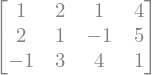

In [10]:
A = sp.Matrix([[1,2,1,4], [2,1,-1,5], [-1,3,4,1]])
A

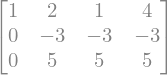

In [11]:
A[1,:] = A[1,:] - 2*A[0,:]
A[2,:] = A[2,:] + 1*A[0,:]
A

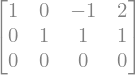

In [12]:
A[1,:] = A[1,:]/-3
A[0,:] = A[0,:] - 2*A[1,:]
A[2,:] = A[2,:] - 5*A[1,:]
A

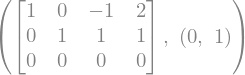

In [6]:
A.rref()